Fase 1: Exploración Inicial
Importen el CSV usando pandas.
Utilicen StandardScaler sobre las columnas Latitud y Longitud y guarden la matriz escalada (X_scaled). Recuerden: un grado de longitud no mide exactamente los mismos kilómetros que un grado de latitud. Escalar nivela el terreno matemático.
Grafiquen los datos crudos usando un Scatter Plot (Longitud en el eje X, Latitud en el eje Y). Si lo hacen correctamente, deberían ver la silueta de la costa del Pacífico.

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

df_raw = pd.read_csv('datasets/logistica_baja_california.csv')
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_raw[['Latitud', 'Longitud']])


In [2]:
X_scaled

array([[ 0.88335238, -0.73514142],
       [ 1.00618974, -0.94540065],
       [ 0.72294016, -1.00890342],
       ...,
       [-4.40047914,  3.45447951],
       [-4.3579893 ,  3.2636921 ],
       [-4.41124399,  3.35464997]], shape=(3100, 2))

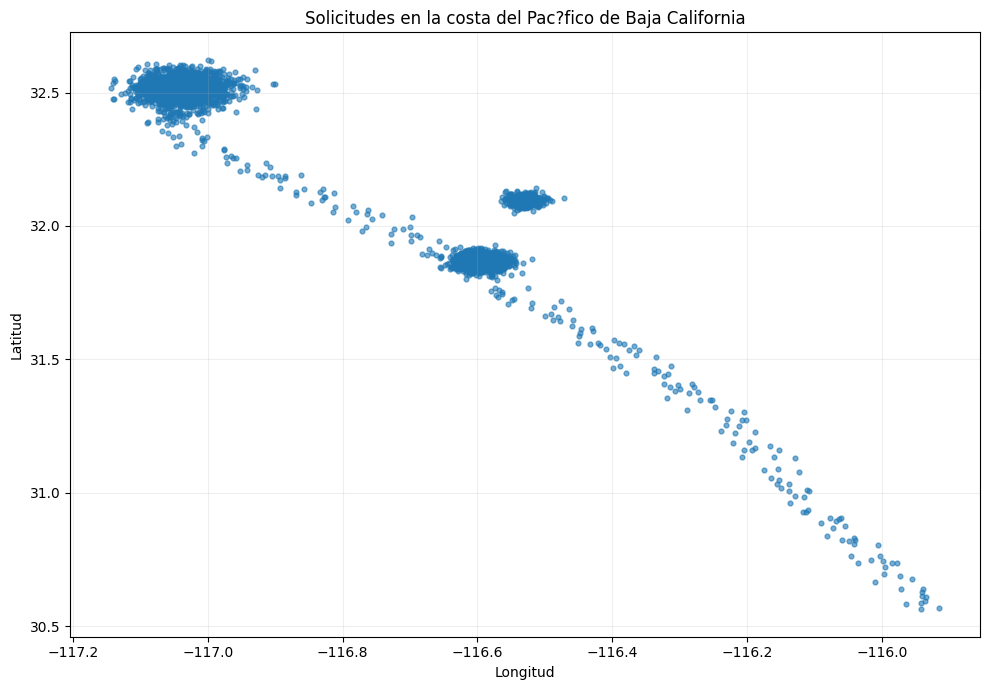

In [3]:
plt.figure(figsize=(10, 7))
plt.scatter(df_raw['Longitud'], df_raw['Latitud'], s=12, alpha=0.6)
plt.title('Solicitudes en la costa del Pac?fico de Baja California')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Fase 2: Misión Estratégica
La mesa directiva aprobó el presupuesto para construir 3 grandes Centros de Distribución (Cedis) en el estado. Necesitan saber exactamente dónde ubicarlos para que queden en el centro geográfico de la demanda general, minimizando los kilómetros de viaje hacia cualquier punto.

El Algoritmo: ¿Qué algoritmo de los vistos en clase se adecua más a este problema?

- Kmeans porque funciona con centroides

El Entregable: Un gráfico de dispersión pintando los 3 clústeres. Extraigan las coordenadas de los cluster_centers_ y grafíquenlos como "X" gigantes sobre el mapa.


La Pregunta de Análisis: Observen las ubicaciones de sus 3 Cedis.
¿Dónde colocó el algoritmo que seleccionaron las Cedis? ¿Consideran que sus localizaciones hacen sentido?
¿Por qué la matemática de este algoritmo provocó esto?

In [ ]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3, random_state=0, n_init="auto").fit(X_scaled)




c:\Users\XxDus\miniconda3\envs\mineria_datos\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=13.
  warnings.warn(


[[-0.9143445   0.97741533]
 [ 0.84292019 -0.90106422]]


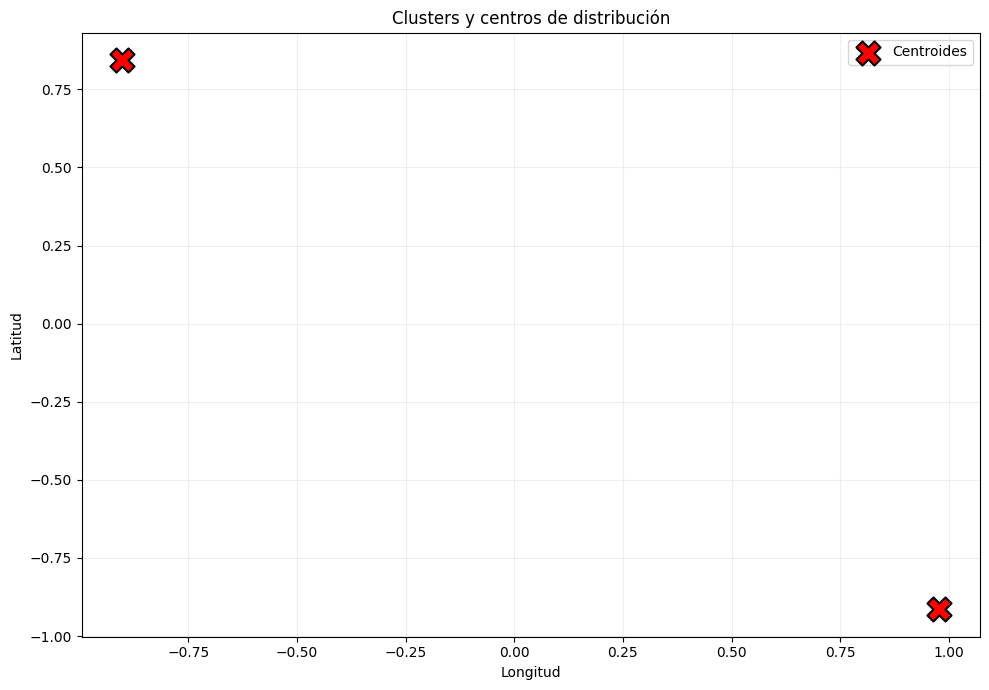

In [ ]:
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(10, 7))
plt.scatter(df_raw['Longitud'], df_raw['Latitud'], s=12, alpha=0.6)
plt.scatter(
    centroids[:, 1],
    centroids[:, 0],
    marker='X',
    s=300,
    c='red',
    edgecolors='black',
    linewidths=1.5
)
plt.title('Solicitudes en la costa del Pacífico de Baja California')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [ ]:
cluster = df